# IS353 - Lab 5b: Information Diffusion và Influence

**MSSV:** 23520588

Đồ thị dùng để thí nghiệm là Zachary Karate Club (34 đỉnh, 78 cạnh). Hai mô hình:

- **Independent Cascade (IC):** nút vừa được kích hoạt có đúng một lần thử lây sang từng hàng xóm chưa active, với xác suất p. Active thì giữ nguyên.
- **Linear Threshold (LT):** mỗi đỉnh có ngưỡng trong [0, 1]. Đỉnh đó active khi tỉ lệ hàng xóm đã active đạt ngưỡng.


## Cài thư viện


In [1]:
%pip install networkx matplotlib numpy scipy scikit-learn


   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   ---------- ----------------------------- 2.1/8.2 MB 8.7 MB/s eta 0:00:01
   --------------------- ------------------ 4.5/8.2 MB 9.2 MB/s eta 0:00:01
   ---------------------------------- ----- 7.1/8.2 MB 10.2 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 10.9 MB/s  0:00:00

   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ---------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Import


In [2]:
%matplotlib inline

import random
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score
from sklearn.model_selection import train_test_split

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 150,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.grid": True,
})


## Hàm dùng chung


In [3]:
def lab_dir() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd() / "BT" / "Lab5b",
        Path(r"d:/Study/IS353/BT/Lab5b"),
    ]
    for folder in candidates:
        if (folder / "requirement.txt").exists() and "Lab5b" in str(folder):
            return folder
    raise FileNotFoundError("Không thấy requirement.txt của Lab 5b.")


LAB = lab_dir()
FIG = LAB / "figures"
FIG.mkdir(exist_ok=True)


def independent_cascade(G, seeds, p=0.1, steps=50, rng=None):
    rng = rng or random
    active = set(seeds)
    newly = set(seeds)
    history = [set(active)]
    for _ in range(steps):
        nxt = set()
        for u in newly:
            for v in G.neighbors(u):
                if v in active:
                    continue
                if rng.random() < p:
                    nxt.add(v)
        if not nxt:
            break
        active |= nxt
        newly = nxt
        history.append(set(active))
    return history


def linear_threshold(G, seeds, thresholds, steps=50):
    active = set(seeds)
    history = [set(active)]
    for _ in range(steps):
        new_active = set()
        for v in G.nodes():
            if v in active:
                continue
            nbrs = list(G.neighbors(v))
            if not nbrs:
                continue
            frac = len(set(nbrs) & active) / len(nbrs)
            if frac >= thresholds[v]:
                new_active.add(v)
        if not new_active:
            break
        active |= new_active
        history.append(set(active))
    return history


def ic_summary(G, seeds, p, trials, seed0, club=None):
    sizes, nsteps, other = [], [], []
    for i in range(trials):
        rng = random.Random(seed0 + i)
        hist = independent_cascade(G, seeds, p=p, rng=rng)
        sizes.append(len(hist[-1]))
        nsteps.append(len(hist) - 1)
        if club is not None and len(seeds) == 1:
            seed_club = club[seeds[0]]
            other.append(sum(club[n] != seed_club for n in hist[-1]))
    return float(np.mean(sizes)), float(np.std(sizes)), float(np.mean(nsteps)), (
        float(np.mean(other)) if other else None
    )


## Karate Club


nodes=34, edges=78


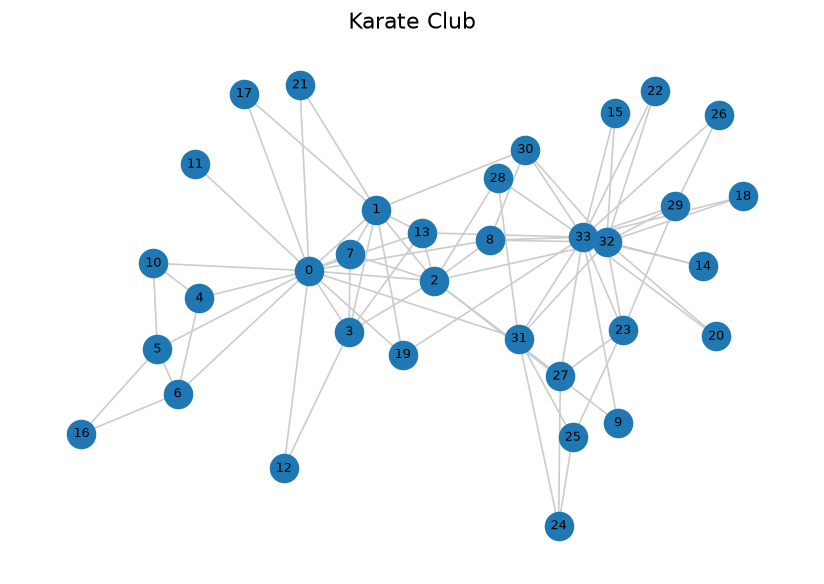

In [4]:
karate = nx.karate_club_graph()
club = nx.get_node_attributes(karate, "club")
degree = dict(karate.degree())
pos = nx.spring_layout(karate, seed=7)
print(f"nodes={karate.number_of_nodes()}, edges={karate.number_of_edges()}")

fig, ax = plt.subplots(figsize=(7, 5))
nx.draw(karate, pos, ax=ax, with_labels=True, node_size=280, font_size=8, edge_color="#cccccc")
ax.set_title("Karate Club")
ax.set_axis_off()
fig.tight_layout()
plt.show()


## Independent Cascade

Một lần chạy từ đỉnh 0 với p = 0.15, rồi quét p và quét bậc của seed. Mỗi ô trung bình dùng 80 lần, seed ngẫu nhiên cố định để chạy lại ra cùng số.


IC demo, seed 0, p=0.15
  step 0: 1 active, other club []
  step 1: 7 active, other club []
  step 2: 9 active, other club [33]
  step 3: 11 active, other club [20, 23, 33]


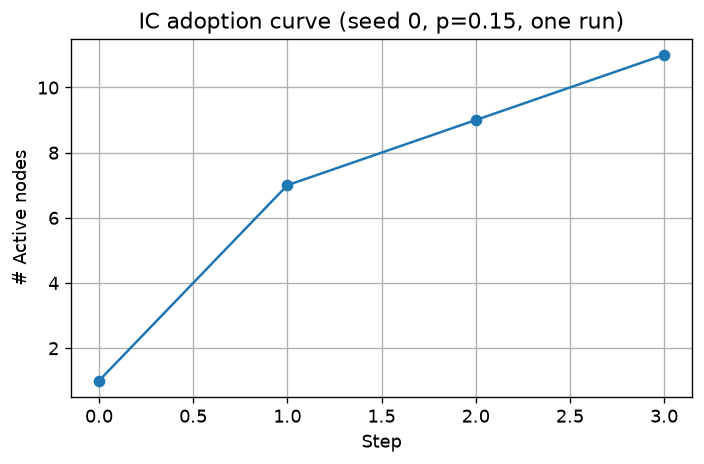


p               size     steps  other club
0.05        1.81 ± 1.09    0.66      0.15
0.10        3.20 ± 2.05    1.30      0.39
0.15        5.50 ± 3.78    2.10      1.25
0.30       17.54 ± 6.94    4.46      8.07
0.50       28.64 ± 2.02    4.60     14.41

seed       deg          size     steps  other club
33          17    5.83 ± 4.22    2.15      1.75
0           16    5.14 ± 3.73    2.00      1.05
11           1    1.68 ± 2.07    0.38      0.07


In [5]:
demo = independent_cascade(karate, [0], p=0.15, rng=random.Random(7))
print("IC demo, seed 0, p=0.15")
for t, active in enumerate(demo):
    other = sorted(n for n in active if club[n] != "Mr. Hi")
    print(f"  step {t}: {len(active)} active, other club {other}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([len(s) for s in demo], marker="o")
ax.set_xlabel("Step")
ax.set_ylabel("# Active nodes")
ax.set_title("IC adoption curve (seed 0, p=0.15, one run)")
fig.tight_layout()
fig.savefig(FIG / "ic_curve.png", bbox_inches="tight")
plt.show()

print()
print(f"{'p':<8}{'size':>12}{'steps':>10}{'other club':>12}")
for p in (0.05, 0.10, 0.15, 0.30, 0.50):
    mean, sd, steps, other = ic_summary(karate, [0], p, 80, 1000 + int(p * 1000), club)
    print(f"{p:<8.2f}{mean:>8.2f} ± {sd:<4.2f}{steps:>8.2f}{other:>10.2f}")

print()
print(f"{'seed':<8}{'deg':>6}{'size':>14}{'steps':>10}{'other club':>12}")
for node in (33, 0, 11):
    mean, sd, steps, other = ic_summary(karate, [node], 0.15, 80, 2000 + node, club)
    print(f"{node:<8}{degree[node]:>6}{mean:>8.2f} ± {sd:<4.2f}{steps:>8.2f}{other:>10.2f}")


## Linear Threshold

Ba bộ ngưỡng, cùng seed 0 và seed 33. Ngưỡng gán một lần rồi giữ nguyên, để chỉ seed đổi.


uniform [0, 1]
  seed 0: size=9, steps=3, curve=[1, 6, 8, 9]
  seed 33: size=8, steps=3, curve=[1, 5, 7, 8]
low [0, 0.4]
  seed 0: size=34, steps=5, curve=[1, 12, 16, 21, 30, 34]
  seed 33: size=34, steps=5, curve=[1, 14, 21, 28, 33, 34]
high [0.6, 1]
  seed 0: size=2, steps=1, curve=[1, 2]
  seed 33: size=1, steps=0, curve=[1]


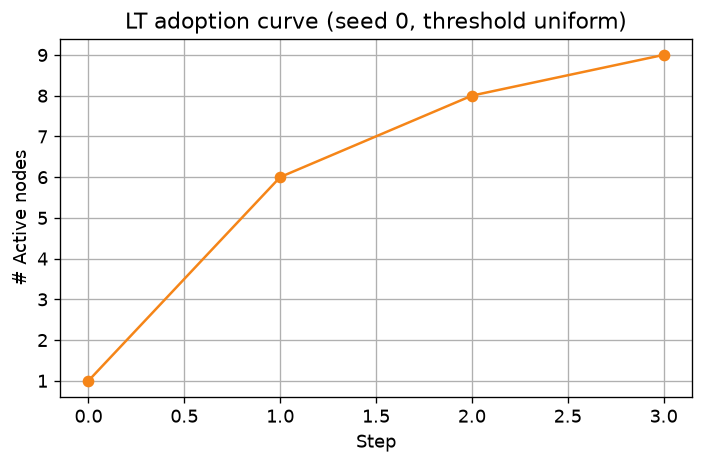

In [6]:
for label, lo, hi, seed in (
    ("uniform [0, 1]", 0.0, 1.0, 11),
    ("low [0, 0.4]", 0.0, 0.4, 12),
    ("high [0.6, 1]", 0.6, 1.0, 13),
):
    rng = random.Random(seed)
    thresholds = {v: rng.uniform(lo, hi) for v in karate.nodes()}
    print(label)
    for node in (0, 33):
        hist = linear_threshold(karate, [node], thresholds)
        print(f"  seed {node}: size={len(hist[-1])}, steps={len(hist) - 1}, curve={[len(s) for s in hist]}")

rng = random.Random(11)
thresholds = {v: rng.uniform(0, 1) for v in karate.nodes()}
hist_lt = linear_threshold(karate, [0], thresholds)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([len(s) for s in hist_lt], marker="o", color="#F58518")
ax.set_xlabel("Step")
ax.set_ylabel("# Active nodes")
ax.set_title("LT adoption curve (seed 0, threshold uniform)")
fig.tight_layout()
fig.savefig(FIG / "lt_curve.png", bbox_inches="tight")
plt.show()


## Vài bước của cascade

Nút active vẽ to và tô cam. Đây là đúng lần chạy IC ở trên, seed 0, p = 0.15.


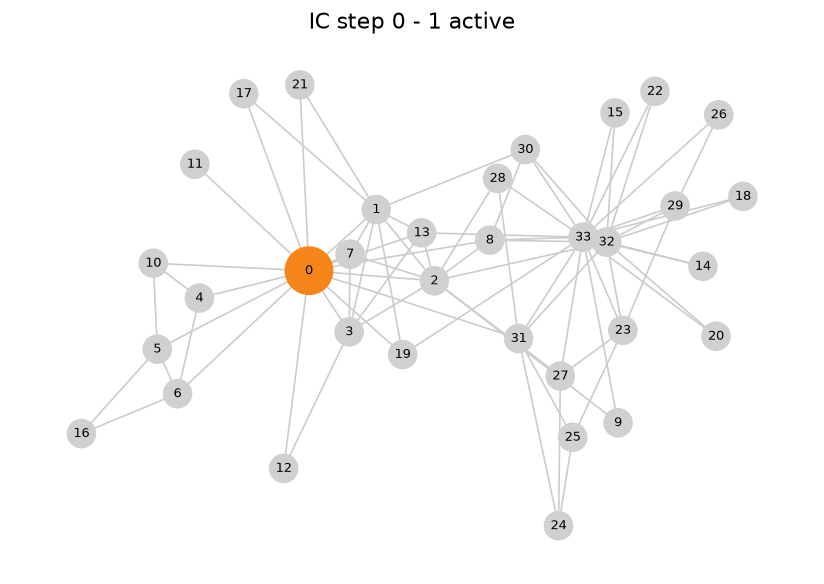

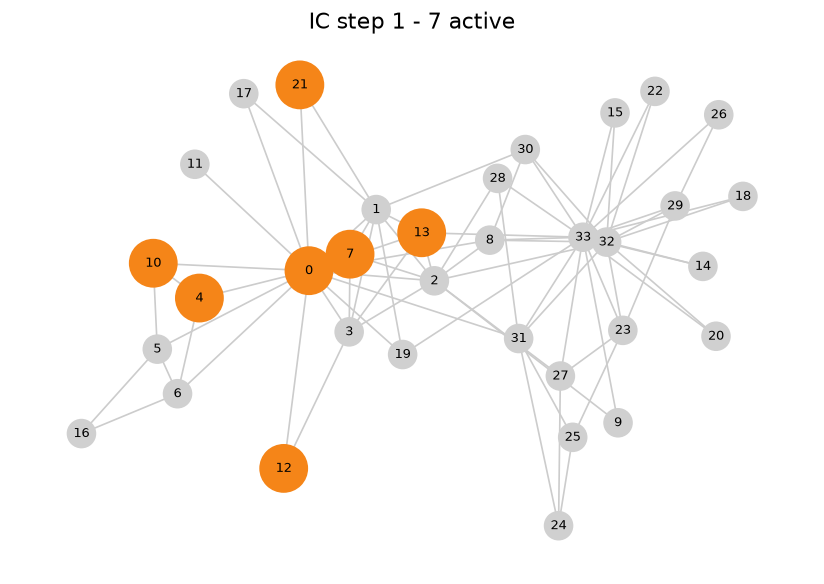

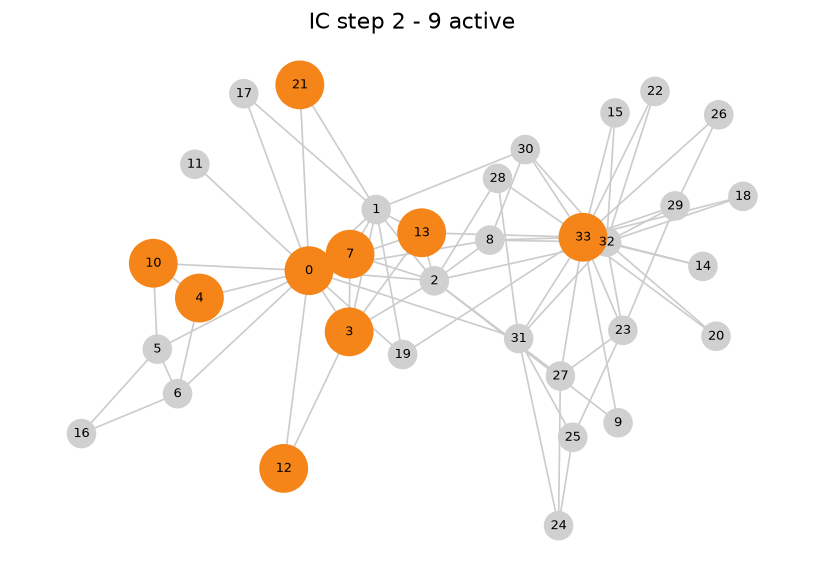

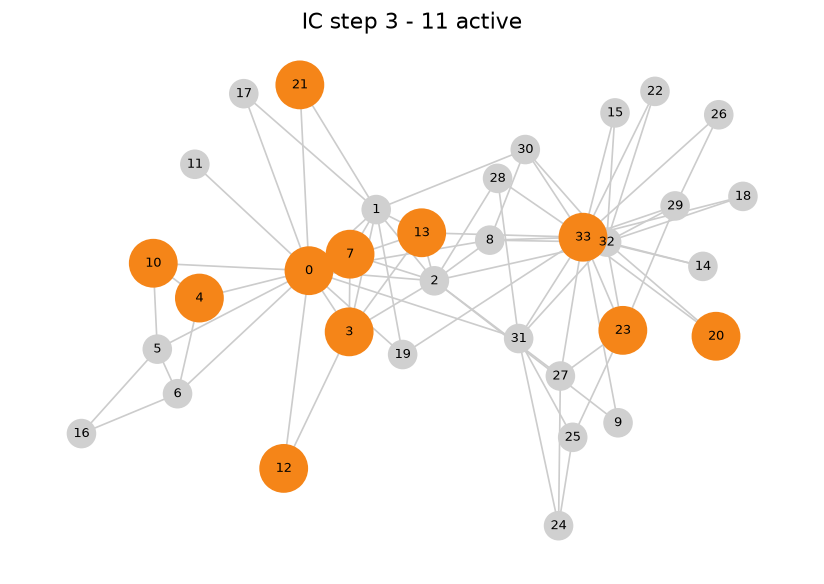

In [7]:
for t, active in enumerate(demo[:4]):
    sizes = [280 + (520 if n in active else 0) for n in karate.nodes()]
    colors = ["#F58518" if n in active else "#d0d0d0" for n in karate.nodes()]
    fig, ax = plt.subplots(figsize=(7, 5))
    nx.draw(
        karate, pos, ax=ax, with_labels=True,
        node_size=sizes, node_color=colors, edge_color="#cccccc", font_size=8,
    )
    ax.set_title(f"IC step {t} - {len(active)} active")
    ax.set_axis_off()
    fig.tight_layout()
    fig.savefig(FIG / f"ic_step_{t}.png", bbox_inches="tight")
    plt.show()


## Influence: random, degree, PageRank

Chọn k = 3 seed, lan bằng IC với p = 0.15, 50 lần. Degree và PageRank cố định. Random lấy bộ seed mới mỗi lần.


degree seeds [33, 0, 32]
pagerank seeds [33, 0, 32]
random   : 8.10 ± 4.63
degree   : 11.56 ± 3.67
pagerank : 11.56 ± 3.67


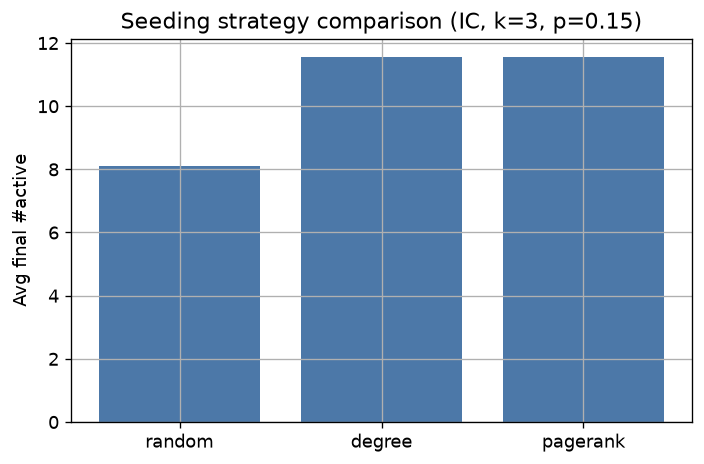

In [8]:
pagerank = nx.pagerank(karate, alpha=0.85)
strategies = {
    "degree": [n for n, _ in sorted(degree.items(), key=lambda x: x[1], reverse=True)[:3]],
    "pagerank": [n for n, _ in sorted(pagerank.items(), key=lambda x: x[1], reverse=True)[:3]],
}
print("degree seeds", strategies["degree"])
print("pagerank seeds", strategies["pagerank"])

strat_means = {}
for name in ("random", "degree", "pagerank"):
    sizes = []
    for i in range(50):
        rng = random.Random(3000 + i)
        if name == "random":
            seeds = rng.sample(list(karate.nodes()), 3)
        else:
            seeds = strategies[name]
        hist = independent_cascade(karate, seeds, p=0.15, rng=rng)
        sizes.append(len(hist[-1]))
    strat_means[name] = (float(np.mean(sizes)), float(np.std(sizes)))
    print(f"{name:9s}: {strat_means[name][0]:.2f} ± {strat_means[name][1]:.2f}")

fig, ax = plt.subplots(figsize=(6, 4))
labels = list(strat_means)
ax.bar(labels, [strat_means[k][0] for k in labels], color="#4C78A8")
ax.set_ylabel("Avg final #active")
ax.set_title("Seeding strategy comparison (IC, k=3, p=0.15)")
fig.tight_layout()
fig.savefig(FIG / "seeding_bar.png", bbox_inches="tight")
plt.show()


## Bonus: đặt cảm biến để phát hiện outbreak

Outbreak xuất phát từ 3 đỉnh bậc thấp: 16 (phe Mr. Hi, bậc 2), 24 và 25 (phe Officer, bậc 3). p = 0.15, 100 lần. Thời gian là bước đầu tiên có một cảm biến active. Lần không chạm cảm biến nào thì không tính vào thời gian trung bình, chỉ tính vào tỉ lệ bắt được.


In [9]:
closeness = nx.closeness_centrality(karate)
sensor_sets = {
    "closeness": [n for n, _ in sorted(closeness.items(), key=lambda x: x[1], reverse=True)[:3]],
    "degree": strategies["degree"],
    "random": [8, 15, 20],
}
outbreak = [16, 24, 25]
print("outbreak", outbreak, "degree", [degree[n] for n in outbreak])
for name, sensors in sensor_sets.items():
    times = []
    for i in range(100):
        rng = random.Random(4000 + i)
        hist = independent_cascade(karate, outbreak, p=0.15, steps=100, rng=rng)
        first = None
        for t, active in enumerate(hist):
            if any(s in active for s in sensors):
                first = t
                break
        times.append(first)
    finite = [t for t in times if t is not None]
    mean_t = float(np.mean(finite)) if finite else float("inf")
    print(f"{name:10s} sensors={sensors} mean_time={mean_t:.2f} detect_rate={len(finite) / 100:.2f}")


outbreak [16, 24, 25] degree [2, 3, 3]
closeness  sensors=[0, 2, 33] mean_time=2.29 detect_rate=0.17
degree     sensors=[33, 0, 32] mean_time=2.18 detect_rate=0.17
random     sensors=[8, 15, 20] mean_time=3.22 detect_rate=0.09


## Optional: dự đoán cạnh nào sẽ truyền

Cặp dương là cạnh đã truyền trong các lần IC. Cặp âm là cặp không có cạnh. Feature: bậc hai đầu, PageRank hai đầu, độ dài đường đi ngắn nhất.


In [10]:
rng = random.Random(42)
pos_pairs = set()
for _ in range(60):
    seed = rng.choice(list(karate.nodes()))
    hist = independent_cascade(karate, [seed], p=0.15, steps=20, rng=rng)
    newly = [hist[0]]
    for t in range(1, len(hist)):
        newly.append(hist[t] - hist[t - 1])
    for t in range(1, len(newly)):
        for u in newly[t - 1]:
            for v in newly[t]:
                if karate.has_edge(u, v):
                    pos_pairs.add((u, v))

pos_list = list(pos_pairs)
neg_list = []
nodes = list(karate.nodes())
while len(neg_list) < len(pos_list):
    u = rng.choice(nodes)
    v = rng.choice(nodes)
    if u == v or (u, v) in pos_pairs or (v, u) in pos_pairs:
        continue
    if not karate.has_edge(u, v):
        neg_list.append((u, v))

pairs = pos_list + neg_list
y = np.array([1] * len(pos_list) + [0] * len(neg_list))
X = []
for u, v in pairs:
    try:
        sp = nx.shortest_path_length(karate, u, v)
    except nx.NetworkXNoPath:
        sp = 1e9
    X.append([karate.degree(u), karate.degree(v), pagerank[u], pagerank[v], float(sp)])
X = np.array(X, dtype=float)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
clf = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
yp = clf.predict(Xte)
proba = clf.predict_proba(Xte)[:, 1]
print(f"pos={len(pos_list)} neg={len(neg_list)}")
print(f"accuracy={accuracy_score(yte, yp):.3f}  AP={average_precision_score(yte, proba):.3f}")
names = ["deg(u)", "deg(v)", "pr(u)", "pr(v)", "shortest path"]
for name, coef in zip(names, clf.coef_[0]):
    print(f"  {name:16s} {coef:.3f}")


pos=76 neg=76
accuracy=1.000  AP=1.000
  deg(u)           0.190
  deg(v)           0.175
  pr(u)            0.003
  pr(v)            0.009
  shortest path    -3.644


## Optional: ego-Facebook

Bậc trung bình khoảng 43.7, nên ngưỡng lan thô là 1/43.7, khoảng 0.023. Ô này chạy 8 lần cho mỗi cách chọn seed. p = 0.05 có thể mất khoảng một phút.


In [11]:
fb_candidates = [
    LAB.parent / "Lab1_2" / "facebook_combined.txt",
    LAB.parent / "Lab3" / "facebook_combined.txt",
    LAB.parent / "Lab4" / "facebook_combined.txt",
    Path.cwd() / "facebook_combined.txt",
]
fb_path = next(path for path in fb_candidates if path.exists())
print(f"Đọc {fb_path}")
facebook = nx.read_edgelist(fb_path, nodetype=int)
fb_degree = dict(facebook.degree())
fb_top_degree = [n for n, _ in sorted(fb_degree.items(), key=lambda x: x[1], reverse=True)[:3]]
fb_pagerank = nx.pagerank(facebook, alpha=0.85)
fb_top_pr = [n for n, _ in sorted(fb_pagerank.items(), key=lambda x: x[1], reverse=True)[:3]]
print("degree seeds", fb_top_degree, [fb_degree[n] for n in fb_top_degree])
print("pagerank seeds", fb_top_pr, [fb_degree[n] for n in fb_top_pr])

jobs = (
    (0.01, "degree", fb_top_degree, 5000),
    (0.01, "pagerank", fb_top_pr, 7000),
    (0.01, "random", None, 5000),
    (0.02, "degree", fb_top_degree, 5000),
    (0.02, "pagerank", fb_top_pr, 7000),
    (0.02, "random", None, 5000),
    (0.05, "degree", fb_top_degree, 5000),
    (0.05, "random", None, 5000),
)
for p, name, seeds, seed0 in jobs:
    sizes, steps = [], []
    for i in range(8):
        rng = random.Random(seed0 + int(p * 1000) + i)
        use = rng.sample(list(facebook.nodes()), 3) if seeds is None else seeds
        hist = independent_cascade(facebook, use, p=p, steps=30, rng=rng)
        sizes.append(len(hist[-1]))
        steps.append(len(hist) - 1)
    print(
        f"p={p:.2f} {name:9s} size={np.mean(sizes):7.1f} ± {np.std(sizes):6.1f} "
        f"steps={np.mean(steps):5.2f}"
    )


Đọc d:\Study\IS353\BT\Lab1_2\facebook_combined.txt
degree seeds [107, 1684, 1912] [1045, 792, 755]
pagerank seeds [3437, 107, 1684] [547, 1045, 792]
p=0.01 degree    size=  207.9 ±   73.2 steps=15.62
p=0.01 pagerank  size=   82.8 ±   42.5 steps= 9.00
p=0.01 random    size=   48.8 ±   78.2 steps= 4.62
p=0.02 degree    size=  841.0 ±   44.4 steps=17.50
p=0.02 pagerank  size=  829.2 ±  163.6 steps=19.88
p=0.02 random    size=   85.1 ±  108.9 steps= 7.88
p=0.05 degree    size= 2114.1 ±  113.3 steps=15.75
p=0.05 random    size= 1722.2 ±  656.9 steps=18.62


## 1. Completed notebook with outputs: IC and LT, adoption curves, cascade steps, and the seeding bar chart.

### 1. Notebook có IC, LT, đường cong adoption, vài bước cascade, và biểu đồ so sánh cách chọn seed.

Phần chạy nằm ở các mục phía trên. Một lần IC từ đỉnh 0, p = 0.15, đi 1, 7, 9 rồi 11 nút.

![IC adoption curve](figures/ic_curve.png)

![IC step 0](figures/ic_step_0.png)

![IC step 1](figures/ic_step_1.png)

![IC step 2](figures/ic_step_2.png)

![IC step 3](figures/ic_step_3.png)

LT với ngưỡng uniform, seed 0, dừng ở 9 nút sau 3 bước.

![LT adoption curve](figures/lt_curve.png)

Ba cách chọn 3 seed, IC p = 0.15, 50 lần. Random trung bình 8.10 nút. Degree và PageRank cùng chọn 33, 0, 32 nên cùng 11.56 nút.

![Seeding comparison](figures/seeding_bar.png)


## 2. What structural factors most affect cascade size and speed in your experiments?

### 2. Yếu tố cấu trúc nào ảnh hưởng mạnh nhất đến kích thước và tốc độ cascade?

Ba yếu tố, đo trên Karate Club.

**Xác suất p của IC.** Seed cố định là đỉnh 0 (bậc 16, phe Mr. Hi), 80 lần:

| p | Số nút active | Số bước | Nút sang phe kia |
| --- | --- | --- | --- |
| 0.05 | 1.81 ± 1.09 | 0.66 | 0.15 |
| 0.10 | 3.20 ± 2.05 | 1.30 | 0.39 |
| 0.15 | 5.50 ± 3.78 | 2.10 | 1.25 |
| 0.30 | 17.54 ± 6.94 | 4.46 | 8.07 |
| 0.50 | 28.64 ± 2.02 | 4.60 | 14.41 |

p thấp thì sóng tắt trong phe của seed. Từ khoảng p = 0.30, sóng đi qua các cầu giữa hai phe và phủ phần lớn đồ thị 34 nút. Số bước tăng rồi dừng quanh 4 đến 5, vì đường kính của Karate Club nhỏ, không cần nhiều bước để đi hết.

Lần vẽ hình (seed 0, p = 0.15, một lần chứ không phải trung bình) đi xa hơn mức trung bình 5.5 nút: bước 1 còn trong phe Mr. Hi (4, 7, 10, 12, 13, 21), bước 2 thêm 3 và chạm 33, bước 3 thêm 20 và 23 bên phe Officer. Trung bình 80 lần chỉ có khoảng 1.3 nút sang phe kia, nên lần này là một lần lan khá xa, không phải lần điển hình.

**Bậc của seed, cùng p = 0.15, 80 lần.**

| Seed | Bậc | Phe | Số nút | Số bước | Sang phe kia |
| --- | --- | --- | --- | --- | --- |
| 33 | 17 | Officer | 5.83 ± 4.22 | 2.15 | 1.75 |
| 0 | 16 | Mr. Hi | 5.14 ± 3.73 | 2.00 | 1.05 |
| 11 | 1 | Mr. Hi | 1.68 ± 2.07 | 0.38 | 0.07 |

Đỉnh 11 chỉ có một hàng xóm, nên chỉ có một lần thử. Hầu hết lần chạy dừng ở 1 nút. Hub có nhiều lần thử ngay bước đầu, nên vừa lớn hơn vừa có cơ hội chạm cầu sang phe kia.

**Ngưỡng của LT.** Cùng một bộ ngưỡng, đổi seed 0 và 33.

| Ngưỡng | Seed 0 | Seed 33 |
| --- | --- | --- |
| uniform [0, 1] | 9 nút, 3 bước | 8 nút, 3 bước |
| thấp [0, 0.4] | 34 nút, 5 bước | 34 nút, 5 bước |
| cao [0.6, 1] | 2 nút, 1 bước | 1 nút, 0 bước |

Ngưỡng thấp thì ai cũng dễ bị kéo theo, hai hub phủ hết đồ thị. Ngưỡng cao thì đỉnh 33, bậc cao nhất, không kích hoạt thêm được ai. Trong LT một đỉnh active khi *tỉ lệ* hàng xóm active vượt ngưỡng. Hàng xóm của hub thường có nhiều bạn khác, nên một hub active chỉ chiếm một phần nhỏ bậc của họ. IC thì ngược lại: bậc cao của seed giúp bắn ra nhiều hướng. LT làm bậc cao của người nhận trở thành cái phanh.

Chọn 3 seed cùng lúc, IC p = 0.15, 50 lần: random 8.10 ± 4.63, degree và PageRank cùng 11.56 ± 3.67. Trên Karate Club top degree và top PageRank trùng một bộ, 33, 0 và 32, nên hai cách hòa nhau và đều hơn random. Random dao động mạnh hơn vì bộ seed mỗi lần một khác.

Tóm lại, p quyết định sóng có tắt sớm hay vượt cầu. Bậc của seed quyết định có bao nhiêu lần thử ở bước đầu. Ngưỡng LT quyết định cụm dày có chịu lan hay tự chặn.


## 3. (Bonus) Outbreak detection results and a brief interpretation.

### 3. (Thêm) Kết quả đặt cảm biến và cách đọc.

Outbreak cố định từ 16, 24, 25. Ba đỉnh này bậc 2 hoặc 3, không trùng bộ cảm biến. p = 0.15, 100 lần.

| Cách chọn | Cảm biến | Thời gian trung bình | Tỉ lệ bắt được |
| --- | --- | --- | --- |
| closeness | 0, 2, 33 | 2.29 | 0.17 |
| degree | 33, 0, 32 | 2.18 | 0.17 |
| random | 8, 15, 20 | 3.22 | 0.09 |

Thời gian chỉ lấy trên những lần có cảm biến thực sự active. Khoảng 83% lần chạy với cảm biến ở hub, và 91% với cảm biến ngẫu nhiên, sóng tắt trước khi chạm cảm biến. p = 0.15 và seed nằm rìa nên đó là điều đáng chờ: phần lớn outbreak không bao giờ ra khỏi chỗ nó bắt đầu.

Trong số lần bắt được, hub nghe sớm hơn nút ngẫu nhiên khoảng một bước, và bắt được nhiều gần gấp đôi (17% so với 9%). Closeness và degree gần như hòa. Hai danh sách chỉ khác một đỉnh, 2 thay cho 32, và cả hai đều là đỉnh nằm giữa đồ thị. Đặt cảm biến ở trung tâm bắt được nhiều đường đi hơn, nhưng không cứu những sóng chết ngay trong cụm biên.


## 4. (Optional) Learning-based predictor metrics and comments.

### 4. (Tùy chọn) Chỉ số của mô hình dự đoán và nhận xét.

60 lần IC, p = 0.15, gom được 76 cặp dương và lấy 76 cặp âm. Logistic regression, 30% làm test: accuracy = 1.000, average precision = 1.000.

Hệ số: bậc nguồn 0.190, bậc đích 0.175, PageRank hai đầu gần 0, shortest path -3.644. Hệ số đường đi lớn hơn hẳn các hệ số kia và mang dấu âm: đường càng dài thì xác suất dự đoán càng thấp.

Accuracy bằng 1 không có nghĩa mô hình hiểu được lan truyền. Cặp dương toàn là cạnh, nên shortest path bằng 1. Cặp âm là cặp không có cạnh, path ít nhất bằng 2. Một ngưỡng trên độ dài đường đi đã tách hai lớp. Mô hình chủ yếu học "có cạnh hay không". Muốn kiểm tra việc truyền thật thì cặp âm cũng phải là cạnh, nhưng là cạnh không truyền trong các lần mô phỏng.


## 5. (Optional) Answer the questions on the ego-Facebook graph.

### 5. (Tùy chọn) Trả lời trên đồ thị ego-Facebook.

4039 đỉnh, 88234 cạnh, bậc trung bình khoảng 43.7. Ba seed, 8 lần, IC.

Top degree là 107, 1684, 1912 (bậc 1045, 792, 755). Top PageRank là 3437, 107, 1684. Khác Karate Club, hai bảng xếp hạng không trùng nhau. Đỉnh 3437 đứng đầu PageRank nhưng bậc chỉ 547, thấp hơn 1912.

| p | Degree | PageRank | Random |
| --- | --- | --- | --- |
| 0.01 | 207.9 ± 73.2 | 82.8 ± 42.5 | 48.8 ± 78.2 |
| 0.02 | 841.0 ± 44.4 | 829.2 ± 163.6 | 85.1 ± 108.9 |
| 0.05 | 2114.1 ± 113.3 |  | 1722.2 ± 656.9 |

Ô PageRank tại p = 0.05 không chạy, vì p = 0.01 và 0.02 đã đủ thấy hai cách chọn hub.

p = 0.01 nằm dưới ngưỡng thô 1/43.7, khoảng 0.023. Seed ngẫu nhiên hầu như tắt (trung bình 49 nút). Seed degree vẫn tới khoảng 208 nút, vì 1045 nhân 0.01 ra khoảng 10 hàng xóm kỳ vọng ngay bước đầu. PageRank chỉ tới khoảng 83, thấp hơn degree, đúng vì seed đứng đầu của nó có bậc nhỏ hơn. p = 0.02 thì hai cách chọn hub gặp nhau quanh 830 đến 840 nút, random vẫn khoảng 85. p = 0.05 thì random cũng bùng, trung bình 1722 nút, khoảng cách với degree thu lại.

Cùng kết luận với Karate Club, chỉ rõ hơn vì đồ thị lớn: p quyết định có vượt ngưỡng lan hay không, và việc seed có phải hub hay không quyết định kích thước khi p còn thấp. Khi p đã cao, seed nào cũng phủ hàng nghìn nút, cách chọn seed bớt quan trọng.
